## Setup và cài đặt các thư viện

In [1]:
# 1. Imports và cấu hình thí nghiệm
import os
import re
import io
import csv
import json
import math
import random
import zipfile
import unicodedata
from collections import Counter
from pathlib import Path
from html import unescape

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Chọn một trong ba chế độ: 'quick', 'standard', 'quality'
RUN_MODE = 'standard'

PRESETS = {
    'quick':    dict(max_chars=2_000_000, max_files=40,  epochs=3,  max_steps=120,  lstm_units=192),
    'standard': dict(max_chars=8_000_000, max_files=120, epochs=8,  max_steps=500,  lstm_units=256),
    'quality':  dict(max_chars=20_000_000, max_files=300, epochs=15, max_steps=1_200, lstm_units=384),
}
assert RUN_MODE in PRESETS, f'RUN_MODE phải thuộc {list(PRESETS)}'
CFG = PRESETS[RUN_MODE]

MAX_CORPUS_CHARS = CFG['max_chars']
MAX_FILES = CFG['max_files']
MAX_CHARS_PER_FILE = 250_000
EPOCHS = CFG['epochs']
MAX_STEPS_PER_EPOCH = CFG['max_steps']
LSTM_UNITS = CFG['lstm_units']

SEQ_LENGTH = 120
SEQ_STRIDE = 60
BATCH_SIZE = 128
EMBEDDING_DIM = 128
MAX_VOCAB_SIZE = 384
MIN_CHAR_FREQUENCY = 3
TRAIN_FRACTION = 0.90
MAX_VALIDATION_STEPS = 100

INPUT_DIR = Path('/kaggle/input')
OUTPUT_DIR = Path('/kaggle/working/lstm_text_generation')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

gpus = tf.config.list_physical_devices('GPU')
print('TensorFlow:', tf.__version__)
print('RUN_MODE:', RUN_MODE, CFG)
print('GPU:', gpus if gpus else 'Không tìm thấy GPU — hãy bật Accelerator trong Kaggle Settings.')

# Mixed precision thường tăng tốc rõ rệt trên GPU Kaggle.
if gpus:
    from tensorflow.keras import mixed_precision
    mixed_precision.set_global_policy('mixed_float16')
    print('Mixed precision policy:', mixed_precision.global_policy())

TensorFlow: 2.20.0
RUN_MODE: standard {'max_chars': 8000000, 'max_files': 120, 'epochs': 8, 'max_steps': 500, 'lstm_units': 256}
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Mixed precision policy: <DTypePolicy "mixed_float16">


## Load dataset

In [2]:
# 2. Hàm tìm dữ liệu và trích xuất văn bản an toàn
PLAIN_EXTS = {'.txt', '.text', '.md'}
HTML_EXTS = {'.html', '.htm', '.xhtml'}
STRUCTURED_EXTS = {'.json', '.jsonl', '.csv', '.parquet'}
ARCHIVE_EXTS = {'.zip', '.epub'}
SUPPORTED_EXTS = PLAIN_EXTS | HTML_EXTS | STRUCTURED_EXTS | ARCHIVE_EXTS

def choose_data_root(input_dir: Path) -> Path:
    if not input_dir.exists():
        raise FileNotFoundError(
            f'Không thấy {input_dir}. Notebook này được thiết kế để chạy trên Kaggle.'
        )
    children = list(input_dir.iterdir())
    preferred = [p for p in children if '10000-vietnamese-books' in p.name.lower()]
    if preferred:
        return preferred[0]
    # Nếu chỉ attach đúng một dataset thì dùng nó; nếu có nhiều dataset, quét toàn bộ Input.
    return children[0] if len(children) == 1 else input_dir

def decode_bytes(raw: bytes) -> str:
    if not raw:
        return ''
    for encoding in ('utf-8-sig', 'utf-16', 'cp1258'):
        try:
            return raw.decode(encoding)
        except (UnicodeDecodeError, UnicodeError):
            pass
    return raw.decode('utf-8', errors='ignore')

def strip_html(text: str) -> str:
    text = re.sub(r'(?is)<(script|style).*?>.*?</\1>', ' ', text)
    text = re.sub(r'(?s)<[^>]+>', ' ', text)
    return unescape(text)

def collect_text_fields(obj, output, limit):
    if sum(map(len, output)) >= limit:
        return
    if isinstance(obj, str):
        output.append(obj)
    elif isinstance(obj, list):
        for item in obj:
            collect_text_fields(item, output, limit)
            if sum(map(len, output)) >= limit:
                break
    elif isinstance(obj, dict):
        priority = ('text', 'content', 'body', 'description', 'chapter', 'title')
        keys = [k for k in priority if k in obj]
        keys += [k for k in obj if k not in keys]
        for key in keys:
            collect_text_fields(obj[key], output, limit)
            if sum(map(len, output)) >= limit:
                break

def text_from_structured(raw_text: str, suffix: str, max_chars: int) -> str:
    try:
        if suffix == '.json':
            output = []
            collect_text_fields(json.loads(raw_text), output, max_chars)
            return '\n'.join(output)[:max_chars]
        if suffix == '.jsonl':
            output = []
            for line in raw_text.splitlines():
                try:
                    collect_text_fields(json.loads(line), output, max_chars)
                except json.JSONDecodeError:
                    continue
                if sum(map(len, output)) >= max_chars:
                    break
            return '\n'.join(output)[:max_chars]
        if suffix == '.csv':
            frame = pd.read_csv(io.StringIO(raw_text), on_bad_lines='skip', low_memory=False)
            text_cols = [c for c in frame.columns if str(c).lower() in {'text', 'content', 'body', 'title'}]
            if not text_cols:
                text_cols = list(frame.select_dtypes(include='object').columns)
            return '\n'.join(frame[text_cols].fillna('').astype(str).agg(' '.join, axis=1))[:max_chars]
    except Exception:
        pass
    return raw_text[:max_chars]

def read_archive(path: Path, max_chars: int) -> str:
    pieces, total = [], 0
    with zipfile.ZipFile(path) as zf:
        names = [n for n in zf.namelist() if Path(n).suffix.lower() in (PLAIN_EXTS | HTML_EXTS | {'.json', '.jsonl'})]
        rng = random.Random(SEED)
        rng.shuffle(names)
        for name in names:
            remaining = max_chars - total
            if remaining <= 0:
                break
            try:
                with zf.open(name) as member:
                    text = decode_bytes(member.read(min(remaining * 4, 2_000_000)))
                suffix = Path(name).suffix.lower()
                if suffix in HTML_EXTS:
                    text = strip_html(text)
                elif suffix in {'.json', '.jsonl'}:
                    text = text_from_structured(text, suffix, remaining)
                text = text[:remaining]
                if text.strip():
                    pieces.append(text)
                    total += len(text)
            except Exception:
                continue
    return '\n\n'.join(pieces)[:max_chars]

def read_parquet_source(path: Path, max_chars: int) -> str:
    # Đọc theo batch để không nạp toàn bộ parquet lớn vào RAM.
    try:
        import pyarrow as pa
        import pyarrow.parquet as pq
    except ImportError as exc:
        raise ImportError('Cần pyarrow để đọc file parquet (Kaggle thường đã cài sẵn).') from exc

    parquet = pq.ParquetFile(path)
    schema = parquet.schema_arrow
    name_map = {name.lower(): name for name in schema.names}
    priority = ('text', 'content', 'body', 'description', 'chapter', 'title')
    columns = [name_map[name] for name in priority if name in name_map]
    if not columns:
        columns = [field.name for field in schema if pa.types.is_string(field.type)]
    if not columns:
        return ''

    pieces, total = [], 0
    for batch in parquet.iter_batches(batch_size=32, columns=columns):
        frame = batch.to_pandas().fillna('').astype(str)
        for value in frame.agg(' '.join, axis=1):
            remaining = max_chars - total
            if remaining <= 0:
                return '\n'.join(pieces)[:max_chars]
            value = value[:remaining]
            if value.strip():
                pieces.append(value)
                total += len(value)
    return '\n'.join(pieces)[:max_chars]

def read_source(path: Path, max_chars: int) -> str:
    suffix = path.suffix.lower()
    if suffix in ARCHIVE_EXTS:
        return read_archive(path, max_chars)
    if suffix == '.parquet':
        return read_parquet_source(path, max_chars)
    with path.open('rb') as handle:
        raw = handle.read(min(max_chars * 4, 4_000_000))
    text = decode_bytes(raw)
    if suffix in HTML_EXTS:
        text = strip_html(text)
    elif suffix in STRUCTURED_EXTS:
        text = text_from_structured(text, suffix, max_chars)
    return text[:max_chars]

DATA_ROOT = choose_data_root(INPUT_DIR)
sources = [p for p in DATA_ROOT.rglob('*') if p.is_file() and p.suffix.lower() in SUPPORTED_EXTS]
sources = sorted(sources, key=lambda p: str(p).lower())

print('DATA_ROOT:', DATA_ROOT)
print(f'Tìm thấy {len(sources):,} nguồn văn bản được hỗ trợ.')
if sources:
    print('Ví dụ:', *[str(p.relative_to(DATA_ROOT)) for p in sources[:8]], sep='\n  - ')
else:
    all_files = [p for p in DATA_ROOT.rglob('*') if p.is_file()]
    raise RuntimeError(
        'Không tìm thấy file văn bản hỗ trợ. Một số file thực tế: ' +
        ', '.join(str(p.name) for p in all_files[:20])
    )

DATA_ROOT: /kaggle/input/datasets
Tìm thấy 10,415 nguồn văn bản được hỗ trợ.
Ví dụ:
  - iambestfeeder/10000-vietnamese-books/output/.....Về Yêu Hoa Cúc - Áo Vàng.txt
  - iambestfeeder/10000-vietnamese-books/output/1. Viết là hành lạc - Trương Thái Du.txt
  - iambestfeeder/10000-vietnamese-books/output/10 Mẩu Truyện Thiền cho Đời Sống Thường Nhật Con Người - Osho.txt
  - iambestfeeder/10000-vietnamese-books/output/10 ngày dẫn đến D-day - David Stafford.txt
  - iambestfeeder/10000-vietnamese-books/output/101 câu chuyện thiền - Muju.txt
  - iambestfeeder/10000-vietnamese-books/output/11 phút - Paulo Coellho.txt
  - iambestfeeder/10000-vietnamese-books/output/12 chiến công của Hercule - Thierry Lefèvre.txt
  - iambestfeeder/10000-vietnamese-books/output/140 vấn đề liên quan đến kinh nguyệt phụ nữ - Trương Dĩ Văn.txt


In [3]:
# 3. Lấy mẫu corpus từ nhiều sách
def normalize_text(text: str) -> str:
    text = unicodedata.normalize('NFC', text)
    text = text.replace('\ufeff', '').replace('\u200b', '').replace('\xa0', ' ')
    text = ''.join(ch for ch in text if ch in '\n\t' or unicodedata.category(ch)[0] != 'C')
    text = re.sub(r'[ \t]+', ' ', text)
    text = re.sub(r' *\n *', '\n', text)
    text = re.sub(r'\n{3,}', '\n\n', text)
    return text.strip()

rng = random.Random(SEED)
shuffled_sources = sources.copy()
rng.shuffle(shuffled_sources)

parts, used_rows, total_chars = [], [], 0
for path in shuffled_sources:
    if len(used_rows) >= MAX_FILES or total_chars >= MAX_CORPUS_CHARS:
        break
    remaining = MAX_CORPUS_CHARS - total_chars
    # Nếu toàn bộ dataset nằm trong một archive/parquet, cho phép đọc đến giới hạn corpus.
    per_file_limit = remaining if path.suffix.lower() in (ARCHIVE_EXTS | {'.parquet'}) else min(MAX_CHARS_PER_FILE, remaining)
    try:
        text = normalize_text(read_source(path, per_file_limit))
    except Exception as exc:
        print(f'Bỏ qua {path.name}: {type(exc).__name__}')
        continue
    if len(text) < 500:
        continue
    text = text[:remaining]
    parts.append(text)
    used_rows.append({'file': str(path.relative_to(DATA_ROOT)), 'characters': len(text)})
    total_chars += len(text)

corpus = '\n\n'.join(parts)
used_files = pd.DataFrame(used_rows)

if len(corpus) < 50_000:
    raise RuntimeError(f'Corpus chỉ có {len(corpus):,} ký tự; cần kiểm tra lại định dạng/đường dẫn dữ liệu.')

print(f'Đã dùng {len(used_files):,} nguồn, tổng cộng {len(corpus):,} ký tự.')
display(used_files.head(10))
print('\nĐoạn văn mẫu sau làm sạch:\n')
print(corpus[:1_000])

Đã dùng 120 nguồn, tổng cộng 7,374,188 ký tự.


,file,characters
0,iambestfeeder/10000-vietnamese-books/output/MÁ...,10669
1,iambestfeeder/10000-vietnamese-books/output/Lặ...,19157
2,iambestfeeder/10000-vietnamese-books/output/Cô...,114936
3,iambestfeeder/10000-vietnamese-books/output/Pa...,19615
4,iambestfeeder/10000-vietnamese-books/output/Dâ...,14409
5,iambestfeeder/10000-vietnamese-books/output/SO...,12090
6,iambestfeeder/10000-vietnamese-books/output/NG...,33761
7,iambestfeeder/10000-vietnamese-books/output/Hó...,249810
8,iambestfeeder/10000-vietnamese-books/output/Th...,122877
9,iambestfeeder/10000-vietnamese-books/output/Cá...,65954



Đoạn văn mẫu sau làm sạch:

Nghiêm Lương Thành
MÁ
Chiến khẽ cựa mình. Đầu nhức như búa bổ. Anh nghe thấy tiếng muỗi leo eo bên tai, lúc gần, lúc xa, lơ mơ làng màng nhưng đầy hăm doạ. Mí mắt nặng tựa kẹp chì, không sao mở ra được. Bả vai bên trái tê bại, nhức nhối như có những mảnh thuỷ tinh nằm xiên xẹo bên trong. Chiến khó nhọc đưa cánh tay còn cử động được quờ quạng quanh mình. Ngón tay chạm phải cái gì đấy ẩm và bở; thính giác bắt gặp mùi hăng nồng của đất mới lẫn với mùi ngai ngái của rễ cây. Gì thế này ? - Anh hốt hoảng - Mình chết rồi ư ? Người ta đã chôn mình rồi sao ? Sự hốt hoảng nhoàng đến như một tia lửa bén vào nhúm cỏ khô, thổi bùng trong anh một chút năng lượng vừa đủ hé được cặp mí mắt sưng mọng. Tối quá. Anh đưa tay lên rờ rẫm một lần nữa. Đúng là mình đang nằm trong một cái hố. Rờ tiếp, thấy trên mình có một tấm gì đấy, mềm mềm như tấm chăn mỏng; dưới lưng là một tấm bố, dưới tấm bố là một tấm gỗ ghép khá dày, kê cao cách mặt hố chừng gang tay. Nhưng tại sao chôn mà 

## Xây dựng vocabulary

In [4]:
# 4. Xây vocabulary và encode corpus
char_counts = Counter(corpus)
kept_chars = [
    ch for ch, count in char_counts.most_common(MAX_VOCAB_SIZE - 1)
    if count >= MIN_CHAR_FREQUENCY
]
idx_to_char = ['�'] + kept_chars  # id=0 dành cho ký tự ngoài vocabulary
char_to_idx = {ch: idx for idx, ch in enumerate(idx_to_char) if idx > 0}
VOCAB_SIZE = len(idx_to_char)

encoded = np.fromiter((char_to_idx.get(ch, 0) for ch in corpus), dtype=np.int32, count=len(corpus))
coverage = float(np.mean(encoded != 0))
split_at = int(len(encoded) * TRAIN_FRACTION)
train_ids = encoded[:split_at]
val_ids = encoded[split_at:]

if len(val_ids) <= SEQ_LENGTH + 1:
    raise RuntimeError('Validation corpus quá ngắn. Hãy tăng MAX_CORPUS_CHARS.')

print(f'Vocabulary: {VOCAB_SIZE} ký tự (gồm [UNK])')
print(f'Coverage: {coverage:.4%}')
print(f'Train: {len(train_ids):,} ký tự | Validation: {len(val_ids):,} ký tự')
print('Các ký tự phổ biến nhất:', char_counts.most_common(20))

vocab_payload = {
    'unknown_token': '�',
    'idx_to_char': idx_to_char,
    'coverage': coverage,
}
with (OUTPUT_DIR / 'vocabulary.json').open('w', encoding='utf-8') as handle:
    json.dump(vocab_payload, handle, ensure_ascii=False, indent=2)

Vocabulary: 384 ký tự (gồm [UNK])
Coverage: 99.9792%
Train: 6,636,769 ký tự | Validation: 737,419 ký tự
Các ký tự phổ biến nhất: [(' ', 1637309), ('n', 648632), ('h', 484327), ('i', 324315), ('g', 320803), ('t', 319036), ('c', 287166), ('a', 178817), ('m', 153187), ('u', 146952), ('đ', 129089), ('à', 120205), ('o', 118316), ('l', 100590), ('ư', 98245), ('y', 91514), ('r', 88073), ('.', 86456), (',', 84812), ('ô', 82145)]


In [5]:
# 5. tf.data pipeline
def make_dataset(ids: np.ndarray, training: bool) -> tf.data.Dataset:
    # Window bắt đầu tại i dùng ids[i:i+SEQ_LENGTH], dự đoán ids[i+SEQ_LENGTH].
    ds = tf.keras.utils.timeseries_dataset_from_array(
        data=ids[:-1],
        targets=ids[SEQ_LENGTH:],
        sequence_length=SEQ_LENGTH,
        sequence_stride=SEQ_STRIDE,
        shuffle=training,
        seed=SEED,
        batch_size=BATCH_SIZE,
    )
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_ids, training=True)
val_ds = make_dataset(val_ids, training=False)

train_batches = int(tf.data.experimental.cardinality(train_ds).numpy())
val_batches = int(tf.data.experimental.cardinality(val_ds).numpy())
steps_per_epoch = min(MAX_STEPS_PER_EPOCH, train_batches)
validation_steps = min(MAX_VALIDATION_STEPS, val_batches)

print(f'Train batches khả dụng: {train_batches:,}; dùng {steps_per_epoch:,}/epoch')
print(f'Validation batches khả dụng: {val_batches:,}; dùng {validation_steps:,}/epoch')

example_x, example_y = next(iter(train_ds))
print('Input batch:', example_x.shape, '| Target batch:', example_y.shape)
print('Ví dụ input:', ''.join(idx_to_char[i] for i in example_x[0].numpy()))
print('Ký tự đích:', repr(idx_to_char[int(example_y[0].numpy())]))

I0000 00:00:1790232835.963220      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790232835.966232      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Train batches khả dụng: 865; dùng 500/epoch
Validation batches khả dụng: 97; dùng 97/epoch
Input batch: (128, 120) | Target batch: (128,)
Ví dụ input: ượng làm tất cả các công việc ấy, còn tôi thì sắp xếp, làm tít, đặt thứ tự và sửa chữa các bài để cho tất cả đều nhất tr
Ký tự đích: 'í'


## Xây dựng mô hình LSTM

In [6]:
# 6. Khởi tạo và compile model
tf.keras.backend.clear_session()

inputs = tf.keras.Input(shape=(SEQ_LENGTH,), dtype=tf.int32, name='character_ids')
x = tf.keras.layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, name='character_embedding')(inputs)
x = tf.keras.layers.LSTM(
    LSTM_UNITS,
    dropout=0.15,
    recurrent_dropout=0.0,
    name='lstm',
)(x)
x = tf.keras.layers.Dropout(0.20)(x)
# dtype float32 giữ logits/loss ổn định khi mixed precision được bật.
logits = tf.keras.layers.Dense(VOCAB_SIZE, dtype='float32', name='next_character')(x)
model = tf.keras.Model(inputs, logits, name='vietnamese_char_lstm')

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
)
model.summary()

Model: "vietnamese_char_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ character_ids (InputLayer)      │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ character_embedding (Embedding) │ (None, 120, 128)       │        49,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ next_character (Dense)          │ (None, 384)            │        98,688 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 542,080 (2.07 MB)

 Trainable params: 542,080 (2.07 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# 7. Huấn luyện
best_model_path = OUTPUT_DIR / 'best_lstm.keras'
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        best_model_path, monitor='val_loss', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=1, min_lr=1e-5, verbose=1
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    callbacks=callbacks,
    verbose=1,
)

history_df = pd.DataFrame(history.history)
history_df.to_csv(OUTPUT_DIR / 'training_history.csv', index=False)
display(history_df)

Epoch 1/8
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.2682 - loss: 3.3793
Epoch 1: val_loss improved from None to 2.50371, saving model to /kaggle/working/lstm_text_generation/best_lstm.keras

Epoch 1: finished saving model to /kaggle/working/lstm_text_generation/best_lstm.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.3140 - loss: 2.8909 - val_accuracy: 0.3626 - val_loss: 2.5037 - learning_rate: 0.0010
Epoch 2/8
364/500 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.3712 - loss: 2.4583

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_loss improved from 2.50371 to 2.35520, saving model to /kaggle/working/lstm_text_generation/best_lstm.keras

Epoch 2: finished saving model to /kaggle/working/lstm_text_generation/best_lstm.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.3776 - loss: 2.4206 - val_accuracy: 0.3898 - val_loss: 2.3552 - learning_rate: 0.0010
Epoch 3/8
499/500 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3921 - loss: 2.3225
Epoch 3: val_loss improved from 2.35520 to 2.22956, saving model to /kaggle/working/lstm_text_generation/best_lstm.keras

Epoch 3: finished saving model to /kaggle/working/lstm_text_generation/best_lstm.keras
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.3993 - loss: 2.2861 - val_accuracy: 0.4142 - val_loss: 2.2296 - learning_rate: 0.0010
Epoch 4/8
364/500 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.4145 - loss: 2.2220
Epoch 4: val_loss improved from 2.22956 to 2.18205, saving model to /kaggle/working/lstm_text_generation/best_lstm.keras

Ep

,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.313969,2.890872,0.362601,2.503712,0.001
1,0.377636,2.420644,0.389779,2.355199,0.001
2,0.399312,2.286135,0.414192,2.229557,0.001
3,0.418764,2.204092,0.424201,2.182054,0.001
4,0.428766,2.145140,0.434860,2.118518,0.001
5,0.437729,2.105648,0.444137,2.093835,0.001
6,0.445563,2.067917,0.448287,2.058166,0.001
7,0.451160,2.043162,0.452356,2.046952,0.001


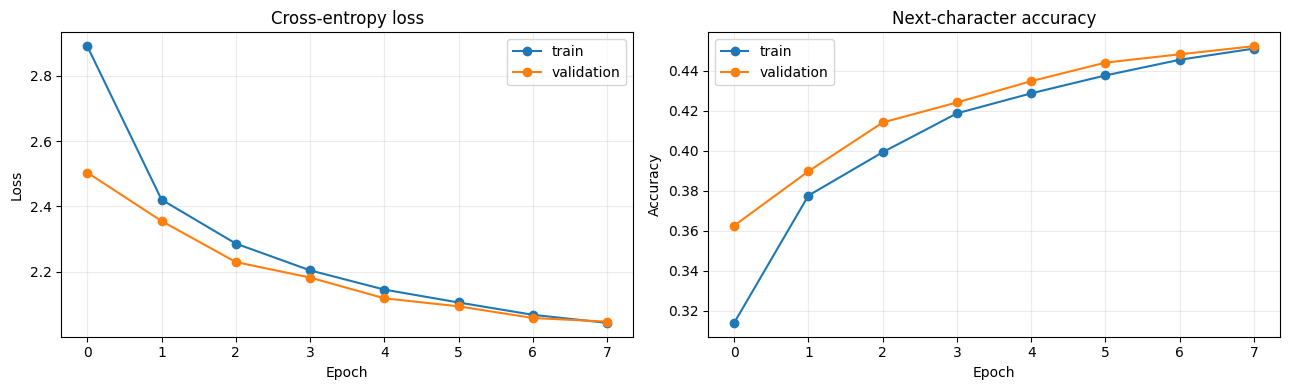

{'accuracy': 0.4523557722568512, 'loss': 2.046952486038208, 'character_perplexity': 7.7442643541910705}
Lưu ý: perplexity ở đây được tính trên ký tự, không so sánh trực tiếp với perplexity mức từ/token.


In [8]:
# 8. Đường học và đánh giá định lượng
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df['loss'], marker='o', label='train')
axes[0].plot(history_df['val_loss'], marker='o', label='validation')
axes[0].set(title='Cross-entropy loss', xlabel='Epoch', ylabel='Loss')
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].plot(history_df['accuracy'], marker='o', label='train')
axes[1].plot(history_df['val_accuracy'], marker='o', label='validation')
axes[1].set(title='Next-character accuracy', xlabel='Epoch', ylabel='Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=160, bbox_inches='tight')
plt.show()

val_metrics = model.evaluate(val_ds, steps=validation_steps, return_dict=True, verbose=0)
char_perplexity = float(math.exp(min(val_metrics['loss'], 20)))
print({**val_metrics, 'character_perplexity': char_perplexity})
print('Lưu ý: perplexity ở đây được tính trên ký tự, không so sánh trực tiếp với perplexity mức từ/token.')

## Sinh văn bản tiếng Việt bằng mô hình LSTM

In [9]:
# 9. Hàm sinh văn bản autoregressive
def choose_seed_text(text: str, length: int = SEQ_LENGTH) -> str:
    paragraphs = [
        re.sub(r'\s+', ' ', p).strip()
        for p in text.split('\n\n')
        if len(re.sub(r'\s+', ' ', p).strip()) >= length
    ]
    if paragraphs:
        paragraph = random.Random(SEED).choice(paragraphs)
        return paragraph[:length]
    return text[:length]

def generate_text(model, prompt: str, num_chars: int = 600, temperature: float = 0.8, top_k: int = 40) -> str:
    if temperature <= 0:
        raise ValueError('temperature phải lớn hơn 0')
    pad_id = char_to_idx.get(' ', 0)
    context = [char_to_idx.get(ch, 0) for ch in prompt][-SEQ_LENGTH:]
    context = [pad_id] * (SEQ_LENGTH - len(context)) + context
    generated = []

    for _ in range(num_chars):
        x = np.asarray(context[-SEQ_LENGTH:], dtype=np.int32)[None, :]
        next_logits = model(x, training=False)[0].numpy().astype(np.float64)
        next_logits[0] = -1e10  # Không sinh token [UNK].
        next_logits /= temperature

        k = min(top_k, VOCAB_SIZE - 1)
        top_ids = np.argpartition(next_logits, -k)[-k:]
        top_values = next_logits[top_ids]
        top_values -= top_values.max()
        probs = np.exp(top_values)
        probs /= probs.sum()
        next_id = int(np.random.choice(top_ids, p=probs))

        context.append(next_id)
        generated.append(idx_to_char[next_id])

    return prompt + ''.join(generated)

seed_text = choose_seed_text(corpus, SEQ_LENGTH)
print('Seed dùng để sinh văn bản:\n', seed_text)

Seed dùng để sinh văn bản:
 Đinh lê vũ Người Cũ 1. Anh thấy hình như năm ngón tay của mình đang nắm chặt lấy ống nghe điện thoại: &quot;Em đang ở tr


In [10]:
# 10. Sinh mẫu ở nhiều temperature và lập bảng báo cáo
def distinct_ngram_ratio(text: str, n: int = 3) -> float:
    grams = [text[i:i+n] for i in range(max(0, len(text) - n + 1))]
    return len(set(grams)) / len(grams) if grams else 0.0

temperatures = [0.5, 0.8, 1.0, 1.2]
sample_rows = []
np.random.seed(SEED)

for temperature in temperatures:
    generated = generate_text(
        model, seed_text, num_chars=600, temperature=temperature, top_k=40
    )
    continuation = generated[len(seed_text):]
    sample_rows.append({
        'temperature': temperature,
        'characters_generated': len(continuation),
        'distinct_3gram': distinct_ngram_ratio(continuation, 3),
        'alphabetic_or_space_ratio': np.mean([ch.isalpha() or ch.isspace() for ch in continuation]),
        'generated_text': generated,
    })

samples_df = pd.DataFrame(sample_rows)
samples_df.to_csv(OUTPUT_DIR / 'generated_samples.csv', index=False, encoding='utf-8-sig')

for row in sample_rows:
    display(Markdown(
        f"### Temperature = {row['temperature']}\n\n"
        f"- Distinct-3: `{row['distinct_3gram']:.3f}`\n"
        f"- Tỷ lệ chữ cái/khoảng trắng: `{row['alphabetic_or_space_ratio']:.3f}`\n\n"
        f"> {row['generated_text'].replace(chr(10), chr(10) + '> ')}"
    ))

### Temperature = 0.5

- Distinct-3: `0.502`
- Tỷ lệ chữ cái/khoảng trắng: `0.998`

> Đinh lê vũ Người Cũ 1. Anh thấy hình như năm ngón tay của mình đang nắm chặt lấy ống nghe điện thoại: &quot;Em đang ở trên nhàn ngiều lại có mặt tranh vuy trảng các như là thiếp qua thuyền they người thát được hiện người như đã đứng thế là thôi chút nhìn cho thương ngày lại là là chiết hần quot; hiều thương lúc những thầy nữa Không nghĩ thiệc là thì chí lần thế qua thông hanh không thì được chúng trên gia còn của một cho thác công nhân cho thiến chững thể nhân chàng thai ra cho chuyện bồn không một chứng thác thấy một đi quy thiết đi thần như việc biều không thì và ngay cô hanh đến tiếp chủ thể người thấy là của chứ của thi thút thứ được có thế chúng và là đánh chi thích nghì chỉ đó người có thông vì hay thì hã

### Temperature = 0.8

- Distinct-3: `0.694`
- Tỷ lệ chữ cái/khoảng trắng: `0.987`

> Đinh lê vũ Người Cũ 1. Anh thấy hình như năm ngón tay của mình đang nắm chặt lấy ống nghe điện thoại: &quot;Em đang ở trại Tin lại. Cũng một hộn lại. Chứng cô lịc hến nghật có bật là mờ bầu biểu tinh nói thể cái để những phói và chỉ lúc tiếng người không tra lạng Hong con lẽ có còn năm trai Tra mà nhiên thuyệc đã, thiết nghĩ trăng tháng và, lại học đạc là nhé gió Thán nó vẫ lạ nghe nàm trải Còn Củ cú nó vại thuy hiễm ông thứng mà đây này thuải công đà em đác nóc thấy khi câm ran hây có thầm nước nữ có để chẳng tiết được ngày thắng che và trong anh Thứ quot;. Tông. Người lại thu công vuạp hật thự thương thể mánh vò thến ngồi mặt ding thì đố lấy Tôi trác với thể thì người Ho vào có. Chu có sang chờ cước của thế g

### Temperature = 1.0

- Distinct-3: `0.759`
- Tỷ lệ chữ cái/khoảng trắng: `0.980`

> Đinh lê vũ Người Cũ 1. Anh thấy hình như năm ngón tay của mình đang nắm chặt lấy ống nghe điện thoại: &quot;Em đang ở trưuệt đã và lận gôi biều về và tiềy và từ cho naư đin phay ông bâi, hồng niớu tới nhòn phững đã kim nỗin chỉ mộ tra nhữ ôi. Ông ngay không Cơn thể bìng hỏi thứng sống chắt sa khách quan khúc kông ngiên rợ như điếu Đầu, hiểu, thệ nguyên ông chó làm chỉ đi Phải cô xa ông người chi lào yệt cô mấy. Nhàn lúp vẻ đến ngùyi tiếm mên hơn mình pháp cầu tran chuyệt đang sau hàm lêm ti.Phang lúc. A chút, đài. Lết Côi giờ đức thông. Từ gii nó chủ diệt lạo Thiếm buung hông hiệu phấy ngủ, sẽ thinh lại lò bă Pha vừa phình Dun tắc kiả phỏi nha lắt hãi ngưề mồn xiề. Thế Trông qua vẻ người vị Dung tháy sao Mở a S

### Temperature = 1.2

- Distinct-3: `0.823`
- Tỷ lệ chữ cái/khoảng trắng: `0.932`

> Đinh lê vũ Người Cũ 1. Anh thấy hình như năm ngón tay của mình đang nắm chặt lấy ống nghe điện thoại: &quot;Em đang ở trong bà dơm cảt: Lai quác hằng truyệng tuộc điêm trạng tới có đện tờ xa rước đần chứ phừa toới. Nhại lối! Diệc, nhan trời Qung-Phùenh lại nhùa có lưng Cũng trông. Còn dọ Bở gình không võ. Đên Trọng ôm son ranh--tổi. Hùn được: Pháp xiến goâm của. Nại Khả, có bị Khôn cay khám chắc nủh trấm các quật làng Vậy ngời.-Mang hục vào đếp vụ” hà Phúng coa mạn gôi Prem có học đìn đảy ra, nhỏn:. Thấy sa lừ và biên: Từ khônh con tỉ lệm&quát. ra đâu.&An: Thứ. -&Bà chân không lên Trự vậy của, Tôm.- Vớn gáci), Pho vước, Phương Câu một khôn” ey: Nổ bì ba.Đàng gì… Tran tên Boại e. Khi cũng nó chúc đứ nha. quốtl. 

In [11]:
# 11. Xuất báo cáo Markdown và toàn bộ artifact
best_epoch = int(history_df['val_loss'].idxmin() + 1)
best_val_loss = float(history_df['val_loss'].min())
best_val_acc = float(history_df.loc[history_df['val_loss'].idxmin(), 'val_accuracy'])

report = [
    '# Báo cáo: LSTM sinh văn bản tiếng Việt',
    '',
    '## Thiết lập',
    '',
    f'- Chế độ chạy: `{RUN_MODE}`',
    f'- Nguồn dữ liệu đã lấy mẫu: **{len(used_files):,}**',
    f'- Số ký tự corpus: **{len(corpus):,}**',
    f'- Vocabulary: **{VOCAB_SIZE}** ký tự; coverage: **{coverage:.3%}**',
    f'- Kiến trúc: Embedding({EMBEDDING_DIM}) → LSTM({LSTM_UNITS}) → Dense({VOCAB_SIZE})',
    '',
    '## Kết quả định lượng',
    '',
    f'- Epoch tốt nhất: **{best_epoch}**',
    f'- Validation loss tốt nhất: **{best_val_loss:.4f}**',
    f'- Validation next-character accuracy tại epoch tốt nhất: **{best_val_acc:.4f}**',
    f'- Character-level perplexity (đánh giá cuối): **{char_perplexity:.3f}**',
    '',
    '## Các mẫu sinh',
    '',
]
for row in sample_rows:
    report += [
        f"### Temperature = {row['temperature']}",
        '',
        f"Distinct-3 = {row['distinct_3gram']:.3f}; tỷ lệ chữ cái/khoảng trắng = {row['alphabetic_or_space_ratio']:.3f}.",
        '',
        row['generated_text'],
        '',
    ]
report += [
    '## Nhận xét',
    '',
    '- Temperature thấp thường cho văn bản ổn định hơn nhưng dễ lặp.',
    '- Temperature cao tăng độ đa dạng, đồng thời tăng nguy cơ sai chính tả/ngữ pháp.',
    '- Mô hình character-level LSTM học được hình thức tiếng Việt và dấu câu, nhưng khả năng duy trì ngữ nghĩa dài hạn còn hạn chế.',
    '- Có thể cải thiện bằng cách tăng dữ liệu/epoch, huấn luyện LSTM nhiều tầng, hoặc chuyển sang mô hình Transformer theo subword.',
]

report_text = '\n'.join(report)
(OUTPUT_DIR / 'generation_report.md').write_text(report_text, encoding='utf-8')
used_files.to_csv(OUTPUT_DIR / 'sampled_files.csv', index=False, encoding='utf-8-sig')

summary = {
    'run_mode': RUN_MODE,
    'corpus_characters': len(corpus),
    'sampled_sources': len(used_files),
    'vocab_size': VOCAB_SIZE,
    'vocab_coverage': coverage,
    'best_epoch': best_epoch,
    'best_validation_loss': best_val_loss,
    'best_validation_accuracy': best_val_acc,
    'character_perplexity': char_perplexity,
}
with (OUTPUT_DIR / 'experiment_summary.json').open('w', encoding='utf-8') as handle:
    json.dump(summary, handle, ensure_ascii=False, indent=2)

display(Markdown(report_text))
print('\nĐã lưu artifact vào:', OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f'  - {path.name}: {path.stat().st_size / 1024:.1f} KB')

# Báo cáo: LSTM sinh văn bản tiếng Việt

## Thiết lập

- Chế độ chạy: `standard`
- Nguồn dữ liệu đã lấy mẫu: **120**
- Số ký tự corpus: **7,374,188**
- Vocabulary: **384** ký tự; coverage: **99.979%**
- Kiến trúc: Embedding(128) → LSTM(256) → Dense(384)

## Kết quả định lượng

- Epoch tốt nhất: **8**
- Validation loss tốt nhất: **2.0470**
- Validation next-character accuracy tại epoch tốt nhất: **0.4524**
- Character-level perplexity (đánh giá cuối): **7.744**

## Các mẫu sinh

### Temperature = 0.5

Distinct-3 = 0.502; tỷ lệ chữ cái/khoảng trắng = 0.998.

Đinh lê vũ Người Cũ 1. Anh thấy hình như năm ngón tay của mình đang nắm chặt lấy ống nghe điện thoại: &quot;Em đang ở trên nhàn ngiều lại có mặt tranh vuy trảng các như là thiếp qua thuyền they người thát được hiện người như đã đứng thế là thôi chút nhìn cho thương ngày lại là là chiết hần quot; hiều thương lúc những thầy nữa Không nghĩ thiệc là thì chí lần thế qua thông hanh không thì được chúng trên gia còn của một cho thác công nhân cho thiến chững thể nhân chàng thai ra cho chuyện bồn không một chứng thác thấy một đi quy thiết đi thần như việc biều không thì và ngay cô hanh đến tiếp chủ thể người thấy là của chứ của thi thút thứ được có thế chúng và là đánh chi thích nghì chỉ đó người có thông vì hay thì hã

### Temperature = 0.8

Distinct-3 = 0.694; tỷ lệ chữ cái/khoảng trắng = 0.987.

Đinh lê vũ Người Cũ 1. Anh thấy hình như năm ngón tay của mình đang nắm chặt lấy ống nghe điện thoại: &quot;Em đang ở trại Tin lại. Cũng một hộn lại. Chứng cô lịc hến nghật có bật là mờ bầu biểu tinh nói thể cái để những phói và chỉ lúc tiếng người không tra lạng Hong con lẽ có còn năm trai Tra mà nhiên thuyệc đã, thiết nghĩ trăng tháng và, lại học đạc là nhé gió Thán nó vẫ lạ nghe nàm trải Còn Củ cú nó vại thuy hiễm ông thứng mà đây này thuải công đà em đác nóc thấy khi câm ran hây có thầm nước nữ có để chẳng tiết được ngày thắng che và trong anh Thứ quot;. Tông. Người lại thu công vuạp hật thự thương thể mánh vò thến ngồi mặt ding thì đố lấy Tôi trác với thể thì người Ho vào có. Chu có sang chờ cước của thế g

### Temperature = 1.0

Distinct-3 = 0.759; tỷ lệ chữ cái/khoảng trắng = 0.980.

Đinh lê vũ Người Cũ 1. Anh thấy hình như năm ngón tay của mình đang nắm chặt lấy ống nghe điện thoại: &quot;Em đang ở trưuệt đã và lận gôi biều về và tiềy và từ cho naư đin phay ông bâi, hồng niớu tới nhòn phững đã kim nỗin chỉ mộ tra nhữ ôi. Ông ngay không Cơn thể bìng hỏi thứng sống chắt sa khách quan khúc kông ngiên rợ như điếu Đầu, hiểu, thệ nguyên ông chó làm chỉ đi Phải cô xa ông người chi lào yệt cô mấy. Nhàn lúp vẻ đến ngùyi tiếm mên hơn mình pháp cầu tran chuyệt đang sau hàm lêm ti.Phang lúc. A chút, đài. Lết Côi giờ đức thông. Từ gii nó chủ diệt lạo Thiếm buung hông hiệu phấy ngủ, sẽ thinh lại lò bă Pha vừa phình Dun tắc kiả phỏi nha lắt hãi ngưề mồn xiề. Thế Trông qua vẻ người vị Dung tháy sao Mở a S

### Temperature = 1.2

Distinct-3 = 0.823; tỷ lệ chữ cái/khoảng trắng = 0.932.

Đinh lê vũ Người Cũ 1. Anh thấy hình như năm ngón tay của mình đang nắm chặt lấy ống nghe điện thoại: &quot;Em đang ở trong bà dơm cảt: Lai quác hằng truyệng tuộc điêm trạng tới có đện tờ xa rước đần chứ phừa toới. Nhại lối! Diệc, nhan trời Qung-Phùenh lại nhùa có lưng Cũng trông. Còn dọ Bở gình không võ. Đên Trọng ôm son ranh--tổi. Hùn được: Pháp xiến goâm của. Nại Khả, có bị Khôn cay khám chắc nủh trấm các quật làng Vậy ngời.-Mang hục vào đếp vụ” hà Phúng coa mạn gôi Prem có học đìn đảy ra, nhỏn:. Thấy sa lừ và biên: Từ khônh con tỉ lệm&quát. ra đâu.&An: Thứ. -&Bà chân không lên Trự vậy của, Tôm.- Vớn gáci), Pho vước, Phương Câu một khôn” ey: Nổ bì ba.Đàng gì… Tran tên Boại e. Khi cũng nó chúc đứ nha. quốtl. 

## Nhận xét

- Temperature thấp thường cho văn bản ổn định hơn nhưng dễ lặp.
- Temperature cao tăng độ đa dạng, đồng thời tăng nguy cơ sai chính tả/ngữ pháp.
- Mô hình character-level LSTM học được hình thức tiếng Việt và dấu câu, nhưng khả năng duy trì ngữ nghĩa dài hạn còn hạn chế.
- Có thể cải thiện bằng cách tăng dữ liệu/epoch, huấn luyện LSTM nhiều tầng, hoặc chuyển sang mô hình Transformer theo subword.


Đã lưu artifact vào: /kaggle/working/lstm_text_generation
  - best_lstm.keras: 6384.7 KB
  - experiment_summary.json: 0.3 KB
  - generated_samples.csv: 3.9 KB
  - generation_report.md: 5.1 KB
  - sampled_files.csv: 11.6 KB
  - training_curves.png: 96.1 KB
  - training_history.csv: 0.8 KB
  - vocabulary.json: 4.0 KB
